# Roman transit search, end to end, with `pytfit5`

This notebook follows one simulated Roman Galactic Bulge Time Domain Survey (GBTDS) light curve through
the steps of our search:

1. **Simulate** a light curve: GBTDS sampling, a transiting planet from the `pytfit5` transit model,
   white noise, stellar variability, data gaps and outliers.
2. **Detrend** it with the moving-polynomial filter, masking transit-like dips, and cut outliers.
3. **Search** it with the periodic Box Least Squares (BLS) search of `bls_cuda`.
4. **Check** the detection: detection thresholds, period aliases, individual transits, odd/even depths,
   single events, the injected signal, and a second search pass.
5. **Model** it with the `pytfit5` transit model: a least-squares fit, then DE-MCMC for the uncertainties.

It uses the settings of our production pipeline (`roman_bench.py`) and runs in a few minutes on a laptop.
See `README.md` and `API.md` for the full reference.

## Setup

`pip install .` in the repository builds the optional C/OpenMP BLS kernel; without it the search falls
back to the Numba kernel with identical results. The detrender and the BLS kernels are compiled with
Numba on first use (a few seconds) and cached afterwards.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

import pytfit5.transitPy5 as tpy5       # configuration, photometry container, detrending
import pytfit5.bls_cpu as gbls          # BLS periodic and single-event searches
import pytfit5.transitmodel as transitm # transit model
import pytfit5.transitfit as transitf   # least-squares fitting
import pytfit5.transitmcmc as tmcmc     # DE-MCMC
import pytfit5.transitplot as transitp  # plots
import pytfit5.keplerian as kep
from pytfit5 import bls_c, synthetic
from pytfit5 import period_validation as pval

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True, "grid.alpha": 0.3})
print("C BLS kernel available:", bls_c.available(),
      "| variant:", bls_c.resolve_variant() if bls_c.available() else bls_c.load_error())
rng = np.random.default_rng(2027)

C BLS kernel available: True | variant: avx512_nodiv


## 1. Simulate a GBTDS light curve

**Sampling.** The GBTDS observes each field every 12.1 minutes during 70.5-day seasons. We simulate
one season (set `NSEASONS = 2` for two; the second starts 182 days after the first), with two data
gaps and 1% of cadences missing at random. Each point integrates for 67 s.

**The star and the planet.** A K dwarf ($M_* = 0.75\,M_\odot$, $R_* = 0.72\,R_\odot$) with a planet
of $R_p/R_* = 0.03$ on a 5.37-day orbit. The model is the `pytfit5` transit model
(`transitm.transitModel`): Mandel & Agol (2002) occultation of a limb-darkened star on a Keplerian
orbit. Its parameters are held in a `transit_model_class`:

| parameter | meaning |
|---|---|
| `rho` | mean stellar density (g/cm³); with the period it sets $a/R_*$ and the duration |
| `t0`, `per` | mid-transit time and period (days) |
| `bb` | impact parameter |
| `rdr` | $R_p/R_*$ |
| `nl3`, `nl4` | quadratic limb darkening in the Kipping (2013) parametrisation $q_1, q_2$ |
| `ecw`, `esw` | $\sqrt{e}\cos\omega$, $\sqrt{e}\sin\omega$ (0 here: circular) |
| `zpt` | photometric zero point |

The model is integrated over each exposure (`itime`) with `nintg` sub-samples.

**Noise.** 1,000 ppm of white noise per point, stellar variability from
`synthetic.generate_stellar_noise` (granulation, activity and spot modulation, each about as large
as the white noise), and 40 upward outliers of 5–20σ (cosmic rays).

In [2]:
CADENCE = 12.1 / 1440.0          # days
SEASON = 70.5                    # days
EXPOSURE = 67.0 / 86400.0        # integration time per point (days)
NSEASONS = 1
SEASON_STARTS = [0.0, 182.0, 365.0]

time_all = np.concatenate([s + np.arange(0.0, SEASON, CADENCE) for s in SEASON_STARTS[:NSEASONS]])
keep = np.ones(time_all.size, bool)
for g0, g1 in [(21.3, 22.1), (47.0, 47.6)]:          # two data gaps
    keep &= ~((time_all > g0) & (time_all < g1))
keep &= rng.random(time_all.size) > 0.01             # 1% of cadences missing
t = time_all[keep]
itime = np.full(t.size, EXPOSURE)

# The star
MSTAR, RSTAR = 0.75, 0.72
SIGMA = 1.0e-3                                       # white noise per point

# The planet (pytfit5 transit model)
sol_true = transitm.transit_model_class()
sol_true.rho = pval.get_stellar_density(MSTAR, RSTAR)   # g/cm^3
sol_true.nl3, sol_true.nl4 = 0.36, 0.30                 # Kipping q1, q2
sol_true.t0, sol_true.per = [2.71], [5.37]
sol_true.bb, sol_true.rdr = [0.3], [0.030]
model = transitm.transitModel(sol_true, t, itime, nintg=41)

stellar = synthetic.generate_stellar_noise(t, granulation_amp=0.3 * SIGMA, activity_amp=1.0 * SIGMA,
                                           rotation_period=11.0, spot_amp=1.0 * SIGMA, seed=7)
flux = model + rng.normal(0.0, SIGMA, t.size) + stellar
k = rng.choice(t.size, 40, replace=False)               # upward outliers (cosmic rays)
flux[k] += rng.uniform(5, 20, k.size) * SIGMA

snr_mf = np.sqrt(np.sum((1.0 - model) ** 2)) / SIGMA    # matched-filter SNR of the injected signal
t14 = kep.transitDuration(sol_true) * 24
n_tr = np.unique(np.round((t[model < 1] - sol_true.t0[0]) / sol_true.per[0])).size
print(f"{t.size} points over {np.ptp(t):.1f} d; depth {1e6 * (1 - model.min()):.0f} ppm, "
      f"duration {t14:.2f} h, {n_tr} transits, matched-filter SNR {snr_mf:.1f}")

# The photometry container used by the detrending, search and fitting routines
phot = tpy5.phot_class()
phot.time, phot.flux = t.copy(), flux.copy()
phot.ferr = np.full(t.size, SIGMA)
phot.itime = itime
phot.tflag = np.zeros(t.size)      # 1 = masked from the detrending fits (e.g. in transit)
phot.icut = np.zeros(t.size)       # 1 = rejected point
phot.flux_f = flux.copy()          # detrended flux (filled by the detrender)

8147 points over 70.5 d; depth 1053 ppm, duration 2.48 h, 13 transits, matched-filter SNR 11.9


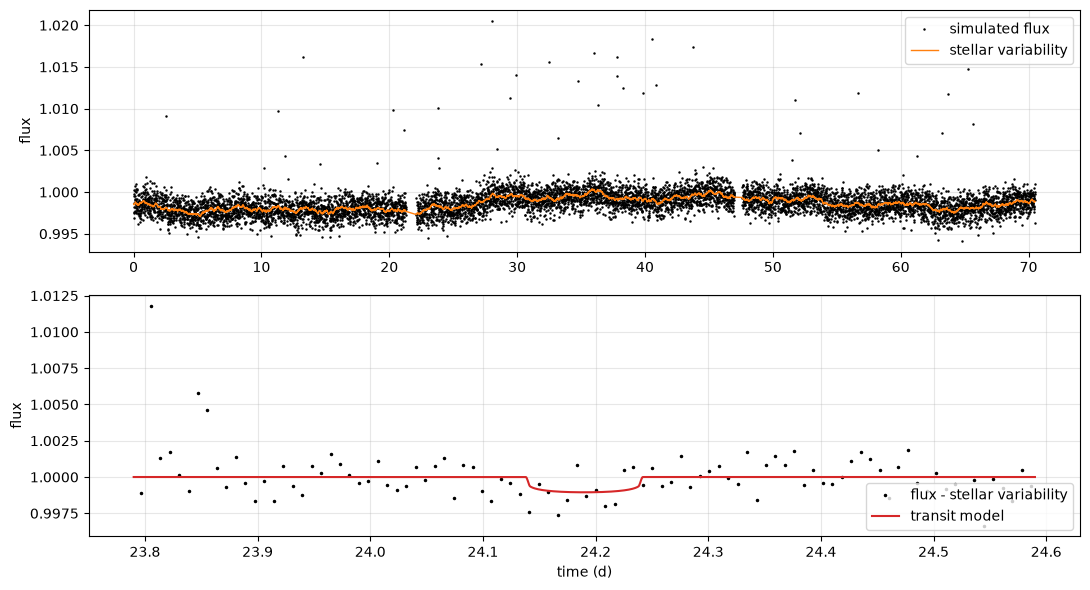

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(t, flux, "k.", ms=1.5, label="simulated flux")
ax[0].plot(t, 1 + stellar, "C1-", lw=1, label="stellar variability")
ax[0].set_ylabel("flux"); ax[0].legend(loc="upper right")
tc = sol_true.t0[0] + 4 * sol_true.per[0]
w = np.abs(t - tc) < 0.4
ax[1].plot(t[w], flux[w] - stellar[w], "k.", ms=3, label="flux - stellar variability")
tt = np.linspace(tc - 0.4, tc + 0.4, 2000)
ax[1].plot(tt, transitm.transitModel(sol_true, tt, np.full(tt.size, EXPOSURE)), "C3-", label="transit model")
ax[1].set_xlabel("time (d)"); ax[1].set_ylabel("flux"); ax[1].legend(loc="lower right")
plt.tight_layout()

## 2. Detrend

`tpy5.run_polyfilter_iterative` removes the stellar variability with a moving polynomial
(`polyfilter`). At each point:

* a polynomial of order `nfitp` (3, cubic) is fitted to the points within ±`boxbin`/2 (here a 3-day
  window), with weights $1/\sigma^2$;
* the window **stops at data gaps** longer than `gapsize` (0.5 d), so the trend is never fitted across
  a gap;
* the fit is **robust to outliers**: points more than 4σ from the fit are clipped and the fit is
  repeated, up to 10 times;
* points flagged in `phot.tflag` are left out of the fits. For a flagged point the trend is
  interpolated from unmasked points on both sides, widening the window if needed.

The "iterative" part flags the transits so that they do not bias the trend. With
`iter_mask_mode = "binned"` the residuals are averaged over 1 hour; stretches whose average is
below −4σ are flagged in `phot.tflag`, and the detrending is repeated until no new points are
flagged.

`tpy5.run_cutoutliers` then flags outliers in `phot.icut`: a point is cut if it lies more than
`dsigclip` (3) times the local point-to-point scatter above both its neighbours. With
`cut_direction = "up"` only upward outliers are cut, so that very short transits are kept. With a
3σ cut about 0.5% of ordinary points are also cut by chance. The cut needs a point to stand above both
neighbours, so an event lasting two or more cadences (here, two outliers that happened to fall on
consecutive cadences) is not cut; the detrender's clipping keeps it out of the trend, and the
dips-only search ignores it. (Downward outliers are left in; the
detrender's clipping keeps them out of the trend, but a deep single point can still look like a short
event to the single-event search below.)

The production pipeline does this for a 3-day and a 1-day window and searches each.

In [4]:
inputs = tpy5.tpy5_inputs_class()          # one configuration object for detrending and search
inputs.mstar, inputs.rstar = MSTAR, RSTAR
inputs.boxbin = 3.0                        # detrending window (days)
inputs.nfitp = 3                           # cubic
inputs.gapsize = 0.5                       # do not fit across gaps longer than this (days)
inputs.iter_mask_mode = "binned"           # transit masking from 1-h averaged residuals
inputs.iter_sigma_threshold = 4.0
inputs.cut_direction = "up"                # cut only upward outliers
inputs.multipro = 1                        # use all available CPU threads
inputs.plots = 0

t0_clock = time.perf_counter()
tpy5.run_polyfilter_iterative(phot, inputs)   # fills phot.flux_f and phot.tflag
tpy5.run_cutoutliers(phot, inputs)            # fills phot.icut
print(f"detrending + outlier cut: {time.perf_counter() - t0_clock:.2f} s (the first call also compiles the kernels)")
print(f"masked as transit-like: {int(phot.tflag.sum())} points; cut as outliers: {int(phot.icut.sum())} points")
amp = (flux[k] - model[k] - stellar[k]) / SIGMA
cut_k = phot.icut[k] == 1
pair = np.array([np.any(np.abs(k - i) == 1) for i in k])   # outliers on consecutive cadences
print(f"injected outliers cut: {cut_k.sum()} of {k.size}; kept: {np.sum(~cut_k & ~pair)} weak ones "
      f"({np.round(np.sort(amp[~cut_k & ~pair]), 1)} sigma, noise included) and {np.sum(~cut_k & pair)} "
      f"on consecutive cadences")

detrending + outlier cut: 0.13 s (the first call also compiles the kernels)
masked as transit-like: 11 points; cut as outliers: 71 points
injected outliers cut: 34 of 40; kept: 2 weak ones ([5.2 5.7] sigma, noise included) and 4 on consecutive cadences


robust scatter after detrending: 1013 ppm


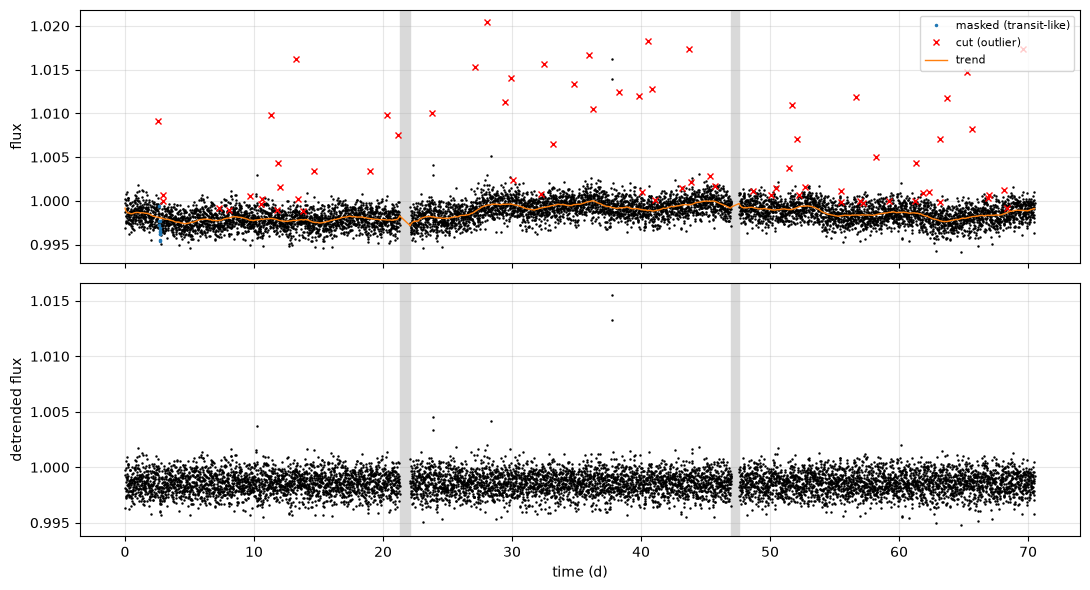

In [5]:
good = phot.icut == 0
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(t, phot.flux, "k.", ms=1.5)
ax[0].plot(t[phot.tflag == 1], phot.flux[phot.tflag == 1], "C0.", ms=3, label="masked (transit-like)")
ax[0].plot(t[~good], phot.flux[~good], "rx", ms=5, label="cut (outlier)")
ax[0].plot(t, phot.flux - phot.flux_f + np.median(phot.flux), "C1-", lw=1, label="trend")
ax[0].set_ylabel("flux"); ax[0].legend(loc="upper right", fontsize=8)
ax[1].plot(t[good], phot.flux_f[good], "k.", ms=1.5)
ax[1].set_ylabel("detrended flux"); ax[1].set_xlabel("time (d)")
for g0, g1 in [(21.3, 22.1), (47.0, 47.6)]:
    for a in ax: a.axvspan(g0, g1, color="0.85")
plt.tight_layout()
print(f"robust scatter after detrending: {1.4826e6 * np.median(np.abs(phot.flux_f[good] - np.median(phot.flux_f[good]))):.0f} ppm")

## 3. Search with BLS

`gbls.bls` is a box-least-squares search (Kovács, Zucker & Mazeh 2002):

* **Frequency grid** from `freq1` (default 2 / time span, i.e. at least two transits) to `freq2` (2 c/d,
  periods down to 0.5 d). The step is proportional to the transit duration expected at each period for
  this star (from `mstar` and `rstar`), so the grid is denser where transits are short; `ofac`
  oversamples it.
* **Box search.** At each trial period the light curve is folded into phase bins (`nbins`, and more at
  long periods so no bin is wider than `max_bin_minutes`). The box with the largest
  $s^2 / [n(N-n)]$ ($s$: summed flux in the box, $n$: points in it) over all start phases and over the
  durations allowed for the star gives the BLS power. With `dips_only = True` only boxes below the
  median count; otherwise brightenings score as highly as transits.
* **Normalisation.** $\sqrt{\text{power}}$ rises toward long periods. `iterative_baseline` subtracts
  a running baseline (strong peaks masked) and divides by the noise of the spectrum, giving the
  normalised power `bpower`.
* **Reported quantities.** The best peak gives the period; the epoch and duration come from its box;
  the depth and the SNR = depth / σ × $\sqrt{n_\text{in}}$ are measured on the light curve folded at
  that period.

The compiled C kernel (AVX-512/AVX2, OpenMP) is used when available. The settings below are the
pipeline's: frequency oversampling 4, at least 1,500 phase bins no wider than 5 minutes, dips only.

In [6]:
inputs.ofac = 4.0
inputs.nbins = 1500
inputs.max_bin_minutes = 5.0
inputs.dips_only = True
inputs.return_spectrum = True              # keep the periodogram for plotting

ts, fs = phot.time[good], phot.flux_f[good]
t0_clock = time.perf_counter()
ans = gbls.bls(inputs, ts, fs)
print(f"BLS ({ans.engine}): {time.perf_counter() - t0_clock:.2f} s, {ans.periods.size} trial periods")
print(f"  P = {ans.bper:.5f} d   T0 = {ans.epo:.4f} d   duration = {24 * ans.tdur:.2f} h")
print(f"  depth = {1e6 * ans.depth:.0f} ppm   SNR = {ans.snr:.1f}   normalised power = {ans.bpower:.1f}")
print(f"  injected: P = {sol_true.per[0]} d, T0 = {sol_true.t0[0]} d, duration = {t14:.2f} h, "
      f"depth ~ {1e6 * (1 - model.min()):.0f} ppm")
print("  (the BLS depth is the mean over the box, so it is below the depth at mid-transit)")

BLS (c:avx512_nodiv): 0.72 s, 25921 trial periods
  P = 5.36885 d   T0 = 2.7154 d   duration = 2.67 h
  depth = 762 ppm   SNR = 9.9   normalised power = 17.1
  injected: P = 5.37 d, T0 = 2.71 d, duration = 2.48 h, depth ~ 1053 ppm
  (the BLS depth is the mean over the box, so it is below the depth at mid-transit)


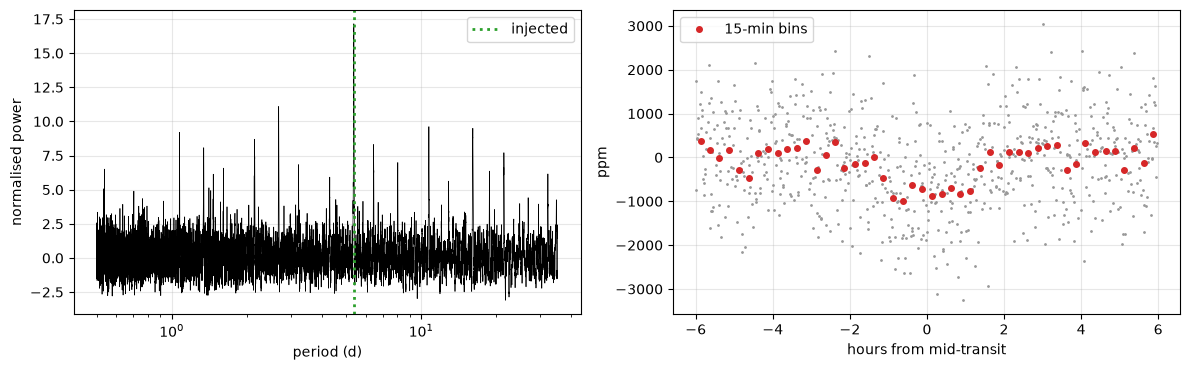

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ans.periods, ans.power, "k-", lw=0.5)
ax[0].axvline(sol_true.per[0], color="C2", ls=":", lw=2, label="injected")
ax[0].set_xscale("log"); ax[0].set_xlabel("period (d)"); ax[0].set_ylabel("normalised power")
ax[0].legend()
ph = ((ts - ans.epo) / ans.bper + 0.5) % 1.0 - 0.5
x = ph * ans.bper * 24
w = np.abs(x) < 6
ax[1].plot(x[w], 1e6 * (fs[w] - np.median(fs)), ".", color="0.6", ms=2)
edges = np.arange(-6, 6.01, 0.25)
idx = np.digitize(x[w], edges)
xb = [x[w][idx == i].mean() for i in range(1, edges.size) if np.any(idx == i)]
yb = [1e6 * (fs[w][idx == i] - np.median(fs)).mean() for i in range(1, edges.size) if np.any(idx == i)]
ax[1].plot(xb, yb, "C3o", ms=4, label="15-min bins")
ax[1].set_xlabel("hours from mid-transit"); ax[1].set_ylabel("ppm"); ax[1].legend()
plt.tight_layout()

### Is it a detection?

The SNR measures how strong a signal is, but it is a poor choice of detection threshold: on noise-only
light curves, the SNR of the best peak rises with residual stellar variability and with the length of
the light curve. The normalised power changes much less. In simulated Roman light curves (the setup
of this notebook, one season), **power ≥ 8.8 together with SNR ≥ 6** gave a false-alarm probability
of 0.5–1% per light curve for both white noise and detrended stellar variability (9.3 for two
seasons). For a survey, set these thresholds from noise-only light curves of the real data.

In [8]:
POWER_MIN = 8.8 if NSEASONS == 1 else 9.3
SNR_MIN = 6.0
detected = (ans.bpower >= POWER_MIN) and (ans.snr >= SNR_MIN)
print(f"power {ans.bpower:.1f} (>= {POWER_MIN}), SNR {ans.snr:.1f} (>= {SNR_MIN}): "
      f"{'DETECTION' if detected else 'no detection'}")

power 17.1 (>= 8.8), SNR 9.9 (>= 6.0): DETECTION


## 4. Check the detection

A peak above threshold can still be the wrong period, a single event, an eclipsing binary, or an
artefact. Some quick checks:

**(a) Period aliases.** `validate_bls_period` scores the folded light curve at $P/2$, $P$, $2P$, ...,
$5P$, testing every possible epoch for the longer periods. Another period replaces the BLS one only if
its SNR is at least 10% higher (a true alias gains about $\sqrt{2}$).

In [9]:
f0 = fs - np.median(fs)                      # the validation works on flux centred on 0
res, tinfo = pval.validate_bls_period(ts, f0, ans, verbose=False)
for fac, P, s, n in zip(res["factors"], res["periods"], res["snrs"], res["n_transits"]):
    print(f"  {fac:3.1f} x P = {P:7.3f} d: SNR {s:5.1f}, {n:2d} transits{'   <- best' if fac == res['best_factor'] else ''}")
print("alias:", res["is_alias"], "| single transit:", res["is_single_transit"])

  0.5 x P =   2.684 d: SNR   7.9, 26 transits
  1.0 x P =   5.369 d: SNR   9.9, 13 transits   <- best
  2.0 x P =  10.738 d: SNR   7.4,  6 transits
  3.0 x P =  16.107 d: SNR   7.2,  5 transits
  4.0 x P =  21.475 d: SNR   6.6,  3 transits
  5.0 x P =  26.844 d: SNR   5.9,  3 transits
alias: False | single transit: False


**(b) Individual transits.** A real periodic signal has transits of similar depth; one dominant event
(and nothing in the others) points to a single transit or an artefact. `transit_info` gives the SNR
of each transit and of all the others folded together (`rest_snr`).

13 transits with data; strongest SNR 5.0, all others folded 8.9; single dominant: False


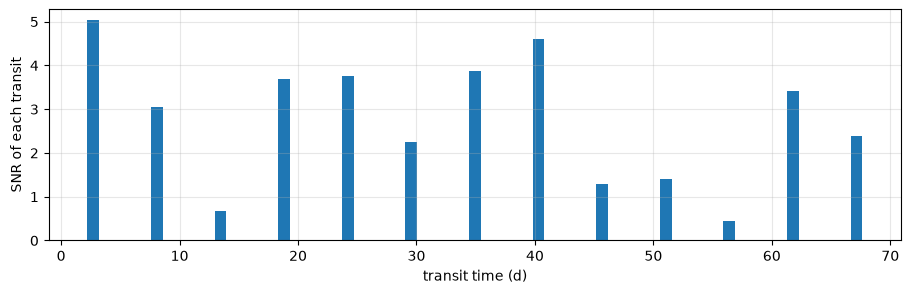

In [10]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(tinfo["transit_times"], tinfo["transit_snrs"], width=1.0, color="C0")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("transit time (d)"); ax.set_ylabel("SNR of each transit")
print(f"{tinfo['n_transits']} transits with data; strongest SNR {tinfo['strongest_snr']:.1f}, "
      f"all others folded {tinfo['rest_snr']:.1f}; single dominant: {tinfo['is_single_dominant']}")

**(c) Odd and even transits.** An eclipsing binary at twice the period shows different depths for
alternate eclipses. Fold at $2P$ from $T_0$ and from $T_0 + P$ and compare.

In [11]:
s_o, d_o, n_o, _ = pval.compute_transit_snr(ts, f0, ans.epo, 2 * ans.bper, ans.tdur)
s_e, d_e, n_e, _ = pval.compute_transit_snr(ts, f0, ans.epo + ans.bper, 2 * ans.bper, ans.tdur)
e_o, e_e = d_o / s_o, d_e / s_e                    # depth / SNR = uncertainty of the depth
print(f"odd:  {1e6 * d_o:5.0f} +- {1e6 * e_o:3.0f} ppm ({n_o} transits)")
print(f"even: {1e6 * d_e:5.0f} +- {1e6 * e_e:3.0f} ppm ({n_e} transits)")
print(f"difference: {abs(d_o - d_e) / np.hypot(e_o, e_e):.1f} sigma")

odd:    679 +- 105 ppm (7 transits)
even:   843 +- 114 ppm (6 transits)
difference: 1.1 sigma


**(d) Single events.** `bls_pulse` runs the periodic search and the single-event (pulse) search on the
same data and keeps the one with the higher SNR. `ans.single` says which won. The pulse search finds
the strongest dip of 1–12 h anywhere in the light curve; for a periodic planet it usually finds one of
its transits, at a lower SNR. Its SNR is the maximum over many trial boxes and is not corrected for
their number, and a single deep downward outlier can produce a high one, so check what it found before
trusting a single-event result.

In [12]:
inputs.return_spectrum = False
ans_p = gbls.bls_pulse(inputs, ts, fs)
pulse = gbls.compute_pulse_search(ts, fs)
print(f"bls_pulse: single = {ans_p.single}, P = {ans_p.bper:.4f} d, SNR = {ans_p.snr:.1f}")
n_near = np.round((pulse["t0"] - ans.epo) / ans.bper)
print(f"pulse search alone: strongest dip at t = {pulse['t0']:.3f} d, {24 * pulse['duration']:.1f} h, SNR {pulse['snr']:.1f}; "
      f"nearest BLS transit at {ans.epo + n_near * ans.bper:.3f} d")

bls_pulse: single = False, P = 5.3689 d, SNR = 9.9
pulse search alone: strongest dip at t = 2.734 d, 3.2 h, SNR 5.3; nearest BLS transit at 2.715 d


**(e) Against the injection.** `compare_bls_injection` measures how many of the injected in-transit
points the BLS solution recovers, allowing for period aliases. (Only possible for simulations, but a
quick way to calibrate a search.)

In [13]:
sol_bls = transitm.transit_model_class()
sol_bls.rho = sol_true.rho
sol_bls.t0, sol_bls.per = [ans.epo], [ans.bper]
sol_bls.bb, sol_bls.rdr = [0.5], [np.sqrt(ans.depth)]
rec = synthetic.compare_bls_injection(phot, sol_true, sol_bls, verbose=False)
print(f"recovered: {rec['is_recovered']}; overlap {rec['overlap_fraction']:.0%}, precision {rec['precision']:.0%}, "
      f"period match: {rec['period_factor_type']}")

recovered: True; overlap 89%, precision 97%, period match: exact


**(f) A second pass.** The pipeline masks the detected transits and searches again, for more planets.
Here there is only one, so the second pass should find nothing above threshold.

In [14]:
dt = np.abs(((ts - ans.epo) / ans.bper + 0.5) % 1.0 - 0.5) * ans.bper
out = dt > ans.tdur                                       # drop points within one duration of each transit
ans2 = gbls.bls(inputs, ts[out], fs[out])
print(f"second pass: P = {ans2.bper:.3f} d, SNR {ans2.snr:.1f}, power {ans2.bpower:.1f} -> "
      f"{'detection' if (ans2.bpower >= POWER_MIN and ans2.snr >= SNR_MIN) else 'nothing above threshold'}")

second pass: P = 2.141 d, SNR 5.7, power 7.0 -> nothing above threshold


## 5. Model the transit

The BLS gives a box. A physical model gives the planet's parameters. We start from the BLS solution:
stellar density from the stellar mass and radius, $T_0$ and $P$ from BLS,
$R_p/R_* \approx \sqrt{\text{depth}}$, and $b = 0.5$, with limb darkening fixed at values for the
bandpass.

The fits use the points flagged in `phot.tflag` (and not cut in `phot.icut`), so we first flag the data
within about two transit durations of each transit with `kep.mark_intransit_data`. We fit the
detrended flux. Transits strong enough to be flagged during detrending were masked from the trend
fits; here each transit has an SNR of only about 3, so few were flagged, but a 3-day window is long
enough compared with the 2.5-hour transit that the detrending barely changes its depth. (For a final
analysis, detrend again with the transits found by the search masked in `phot.tflag`.)

**Least squares.** `transitf.fitTransitModel` fits the parameters named in `params_to_fit` and returns
a new `transit_model_class` with values and uncertainties. At this SNR the light curve alone hardly
separates the stellar density from the impact parameter (both change the duration and the shape of
ingress and egress), so here we hold ρ* at the value from the stellar mass and radius and fit the rest.

In [15]:
sol = transitm.transit_model_class()
sol.rho = pval.get_stellar_density(inputs.mstar, inputs.rstar)
sol.nl3, sol.nl4 = 0.36, 0.30                    # limb darkening (Kipping q1, q2), fixed
sol.t0, sol.per = [ans.epo], [ans.bper]
sol.bb, sol.rdr = [0.5], [np.sqrt(ans.depth)]

phot_fit = phot[phot.icut == 0]                  # a copy without the cut points
kep.mark_intransit_data(phot_fit, sol, tdurcut=2.0)
print(f"{int(phot_fit.tflag.sum())} points near transits used in the fit")

sol_fit = transitf.fitTransitModel(sol, ["zpt", "t0", "per", "bb", "rdr"], phot_fit)
transitp.printParams(sol_fit)

570 points near transits used in the fit
ρ* (g/cm³):                     2.8328801 ± 0.0000000
c1:                                   0.0 ± 0.0
c2:                                   0.0 ± 0.0
q1:                                  0.36 ± 0.0
q2:                                   0.3 ± 0.0
Dilution:                             0.0 ± 0.0
Velocity Offset:                      0.0 ± 0.0
Photometric zero point:        -1.366e-03 ± 4.955e-05
Error scale factor:                   1.0 ± 0.0
t0 (days):                      2.7110090 ± 0.0058894
Period (days):                  5.3700398 ± 0.0011883
Impact parameter:               0.1481966 ± 0.3701414
Rp/R*:                          0.0278190 ± 0.0016615
sqrt(e)cos(w):                        0.0 ± 0.0
sqrt(e)sin(w):                        0.0 ± 0.0
RV Amplitude (m/s):                   0.0 ± 0.0
Thermal eclipse depth (ppm):          0.0 ± 0.0
Ellipsoidal variations (ppm):         0.0 ± 0.0
Albedo amplitude (ppm):               0.0 ± 0.0


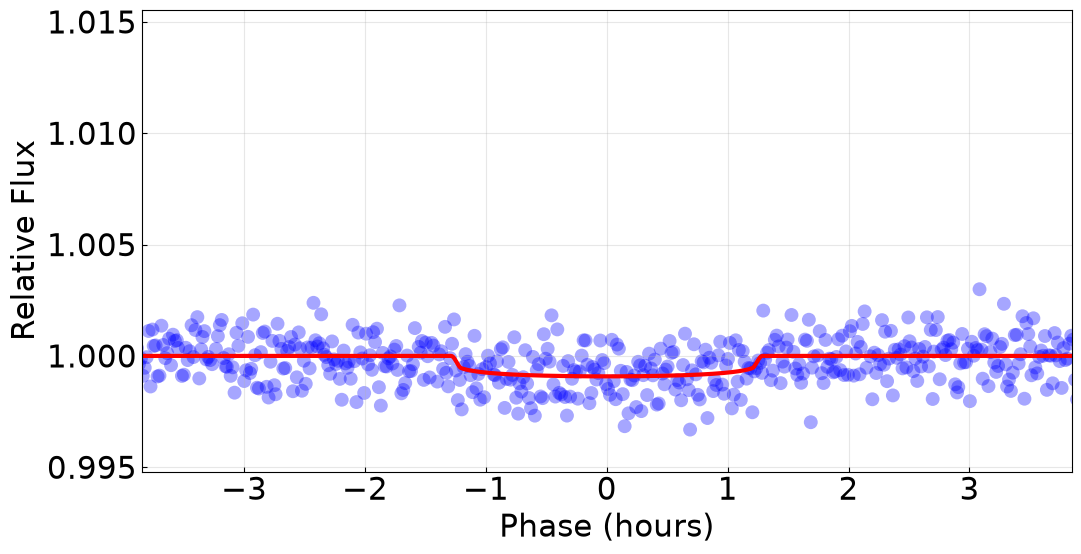

In [16]:
transitp.plotTransit(phot_fit, sol_fit, pl_to_plot=1)

**DE-MCMC.** `transitmcmc.demcmcRoutine` samples the posterior with differential-evolution Markov
chains, starting from the least-squares solution. `genmcmcInput` builds the log-probability function,
the starting vector and the initial step sizes; `cutOutOfTransit` keeps only the data near the
transits. Now ρ* is fitted too, with a Gaussian prior from the star (`transitmcmc.priors_class`;
20% here); any parameter can take such a prior. The 10 entries of `params` are: test-chain length, main-chain length, increment per loop,
burn-in fraction, steps and burn-in for the step-size correlation, thinning, maximum number of loops,
and the Gelman-Rubin convergence criteria for the chain and the buffer. The chain here is short, to
keep the notebook quick; use longer chains (e.g. `[10000, 50000, 50000, 0.2, 10000, 1000, 101, 5, 1.02, 1.2]`)
for results.

In [17]:
import contextlib, io

params_to_fit = ["rho", "zpt", "t0", "per", "bb", "rdr"]
priors = tmcmc.priors_class()
priors.rho = [sol.rho, 0.2 * sol.rho, 0.2 * sol.rho]        # [mean, sigma_up, sigma_lo]
sol_fit.drho = 0.2 * sol.rho                                 # initial step size for rho

lnprob, x, beta = tmcmc.genmcmcInput(sol_fit, params_to_fit, priors=priors)
phot_cut = tmcmc.cutOutOfTransit(sol_fit, phot_fit)
params = [2000, 4000, 4000, 0.2, 2000, 200, 1, 2, 1.02, 1.2]
t0_clock = time.perf_counter()
log = io.StringIO()
with contextlib.redirect_stdout(log):                       # the routine reports its progress
    chain, accept, burnin = tmcmc.demcmcRoutine(x, beta, phot_cut, sol_fit.to_array(),
                                                sol_fit.err_to_array(), params, lnprob)
lines = log.getvalue().splitlines()
gr = max(i for i, l in enumerate(lines) if l.startswith("Gelman-Rubin"))
print(f"DE-MCMC: {time.perf_counter() - t0_clock:.0f} s, chain {chain.shape}, burn-in {burnin}")
print("Gelman-Rubin R for", params_to_fit, ":", [l.split()[1] for l in lines[gr + 2:gr + 2 + len(params_to_fit)]])
sol_mcmc = tmcmc.getParams(chain, burnin, sol_fit, params_to_fit)
transitp.printParams(sol_mcmc)

DE-MCMC: 78 s, chain (19203, 6), burn-in 3840
Gelman-Rubin R for ['rho', 'zpt', 't0', 'per', 'bb', 'rdr'] : ['1.0057', '1.0169', '1.0104', '1.0078', '1.0023', '1.0068']
ρ* (g/cm³):                     2.4001898 ± 0.5002134
c1:                                   0.0 ± 0.0
c2:                                   0.0 ± 0.0
q1:                                  0.36 ± 0.0
q2:                                   0.3 ± 0.0
Dilution:                             0.0 ± 0.0
Velocity Offset:                      0.0 ± 0.0
Photometric zero point:        -1.363e-03 ± 4.981e-05
Error scale factor:                   1.0 ± 0.0
t0 (days):                      2.7143762 ± 0.0065858
Period (days):                  5.3693440 ± 0.0009187
Impact parameter:               0.1897240 ± 0.1472006
Rp/R*:                          0.0275884 ± 0.0017477
sqrt(e)cos(w):                        0.0 ± 0.0
sqrt(e)sin(w):                        0.0 ± 0.0
RV Amplitude (m/s):                   0.0 ± 0.0
Thermal eclipse depth (ppm)

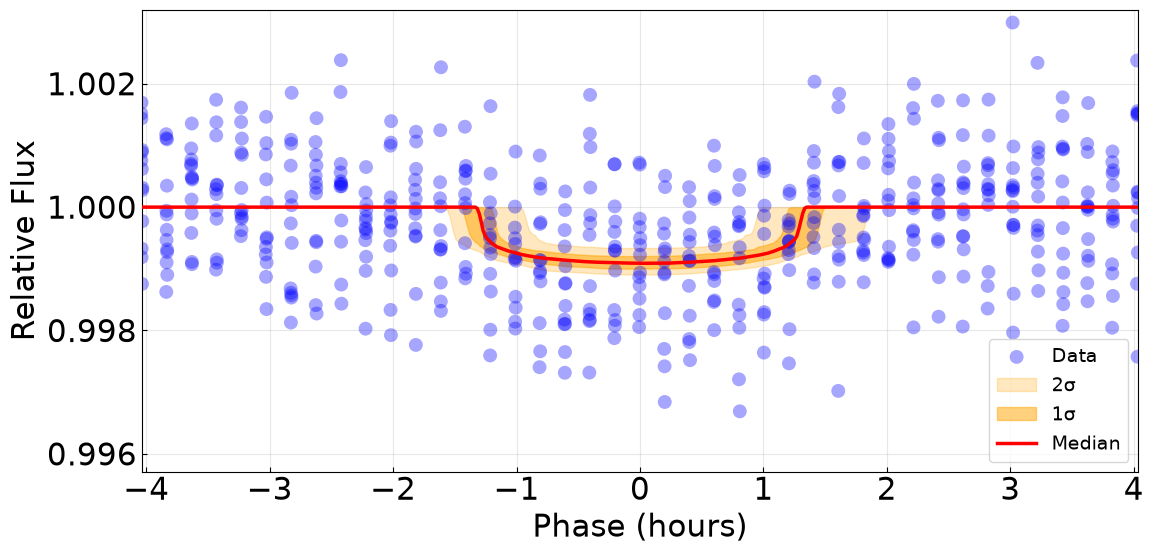

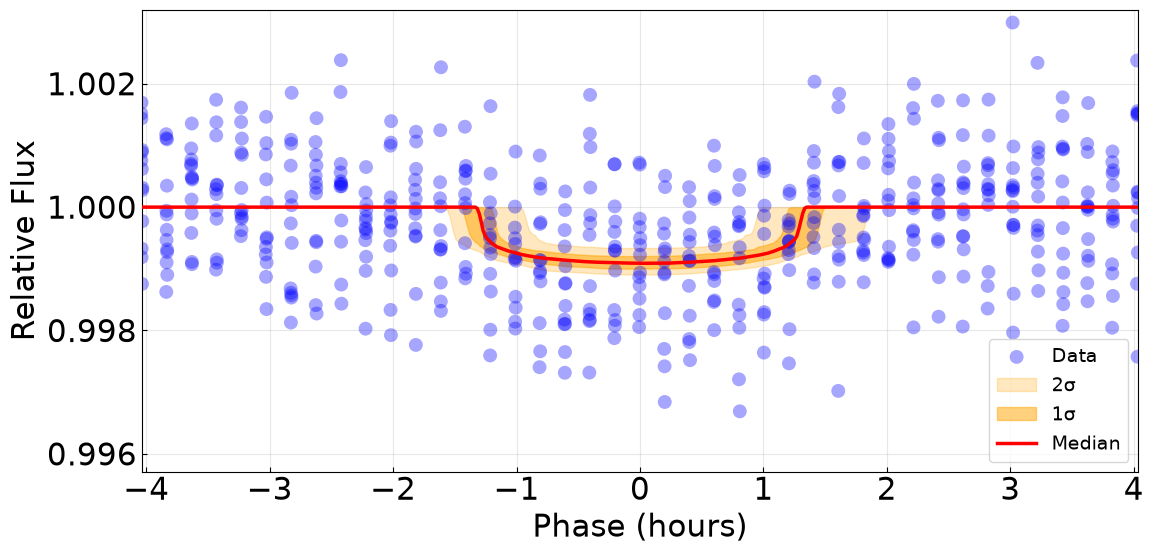

In [18]:
transitp.plotTransitMCMC(chain, burnin, sol_fit, params_to_fit, phot_cut, pl_to_plot=1, n_samples=200)

### Recovered against injected

In [19]:
rows = [("rho (g/cm3)", "rho", None), ("T0 (d)", "t0", 0), ("P (d)", "per", 0), ("b", "bb", 0), ("Rp/R*", "rdr", 0)]
def val(s, name, i):
    v = getattr(s, name); return v[i] if i is not None else v
def err(s, name, i):
    if s is sol_fit and name == "rho": return np.nan        # held fixed in the least-squares fit
    e = getattr(s, "d" + name, None)
    if e is None: return np.nan
    e = e[i] if i is not None else e
    return np.nan if e is None else float(e)
bls_vals = {"rho": sol.rho, "t0": ans.epo, "per": ans.bper, "bb": np.nan, "rdr": np.sqrt(ans.depth)}
print("(BLS column: rho from the stellar mass and radius; least squares: rho held fixed)")
print(f"{'':12s} {'injected':>10s} {'BLS':>10s} {'least squares':>22s} {'DE-MCMC':>22s}  {'(MCMC-inj)/err':>14s}")
for label, name, i in rows:
    tv, mv, me = val(sol_true, name, i), val(sol_mcmc, name, i), err(sol_mcmc, name, i)
    print(f"{label:12s} {tv:10.5f} {bls_vals[name]:10.5f} {val(sol_fit, name, i):11.5f} +- {err(sol_fit, name, i):8.5f} "
          f"{mv:11.5f} +- {me:8.5f}  {(mv - tv) / me:14.1f}")

(BLS column: rho from the stellar mass and radius; least squares: rho held fixed)
               injected        BLS          least squares                DE-MCMC  (MCMC-inj)/err
rho (g/cm3)     2.83288    2.83288     2.83288 +-      nan     2.40019 +-  0.50021            -0.9
T0 (d)          2.71000    2.71539     2.71101 +-  0.00589     2.71438 +-  0.00659             0.7
P (d)           5.37000    5.36885     5.37004 +-  0.00119     5.36934 +-  0.00092            -0.7
b               0.30000        nan     0.14820 +-  0.37014     0.18972 +-  0.14720            -0.7
Rp/R*           0.03000    0.02760     0.02782 +-  0.00166     0.02759 +-  0.00175            -1.4


## Next steps

* **The production pipeline.** `roman_bench.py` (in the Roman search repository) runs exactly these
  steps for many light curves in parallel: two detrending windows (3 and 1 days), up to five search
  passes per window with the detected transits masked between passes, and the single-event search.
  It records the SNR and the normalised power of every pass.
* **Two seasons.** Set `NSEASONS = 2` above: the search then uses the two-season threshold
  (power ≥ 9.3), and the period is measured far more precisely.
* **Your own data.** Replace section 1 with `tpy5.readphot(filename)` (columns time, flux, error) or
  fill a `phot_class` from your arrays.